# Lab - EDA Bivariate Analysis: Amazon UK Product Insights Part II

**Objective**: Delve into the dynamics of product pricing on Amazon UK to uncover insights that can inform business strategies and decision-making.

**Dataset**: [Amazon UK product dataset](https://www.kaggle.com/datasets/asaniczka/uk-optimal-product-price-prediction/)

## Imports & Load Data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import scipy.stats as ss

# Load the dataset
# Your code here

In [2]:
amazon_uk_product_df = pd.read_csv("amz_uk_price_prediction_dataset.csv")

In [3]:
amazon_uk_product_df.head()

,uid,asin,title,stars,reviews,price,isBestSeller,boughtInLastMonth,category
0,1,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
1,2,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",4.7,98099,23.99,True,0,Hi-Fi Speakers
2,3,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",4.7,15308,21.99,False,0,Hi-Fi Speakers
3,4,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",4.7,7205,31.99,False,0,Hi-Fi Speakers
4,5,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,4.6,1881,17.99,False,0,Hi-Fi Speakers


In [4]:
amazon_uk_product_df = amazon_uk_product_df[amazon_uk_product_df.columns[amazon_uk_product_df.isnull().mean() < 0.8]]

In [5]:
amazon_uk_product_df.drop("uid", inplace=True, axis=1)

In [7]:
potential_categorical_from_numerical = amazon_uk_product_df.select_dtypes("number").loc[:, amazon_uk_product_df.select_dtypes("number").nunique() < 30]
potential_categorical_from_numerical

,boughtInLastMonth
0,0
1,0
2,0
3,0
4,0
...,...
2443646,0
2443647,0
2443648,0
2443649,0


In [8]:
amazon_uk_product_df_categorical = pd.concat([amazon_uk_product_df.select_dtypes("object"), potential_categorical_from_numerical], axis=1)

In [10]:
amazon_uk_product_df_categorical.head()

,asin,title,category,boughtInLastMonth
0,B09B96TG33,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers,0
1,B01HTH3C8S,"Anker Soundcore mini, Super-Portable Bluetooth...",Hi-Fi Speakers,0
2,B09B8YWXDF,"Echo Dot (5th generation, 2022 release) | Big ...",Hi-Fi Speakers,0
3,B09B8T5VGV,"Echo Dot with clock (5th generation, 2022 rele...",Hi-Fi Speakers,0
4,B09WX6QD65,Introducing Echo Pop | Full sound compact Wi-F...,Hi-Fi Speakers,0


In [9]:
amazon_uk_product_df_numerical = amazon_uk_product_df.select_dtypes("number").drop(columns=potential_categorical_from_numerical.columns)

In [12]:
amazon_uk_product_df_numerical.head()

,stars,reviews,price
0,4.7,15308,21.99
1,4.7,98099,23.99
2,4.7,15308,21.99
3,4.7,7205,31.99
4,4.6,1881,17.99


---
## Part 1: Analyzing Best-Seller Trends Across Product Categories

**Objective**: Understand the relationship between product categories and their best-seller status.

### 1.1 Crosstab Analysis
Create a crosstab between the product `category` and the `isBestSeller` status.
Are there categories where being a best-seller is more prevalent?

*Hint: Calculate the proportion of best-sellers for each category and sort in descending order.*

In [13]:
crosstab_result = pd.crosstab(amazon_uk_product_df["category"], amazon_uk_product_df["isBestSeller"])

crosstab_result

isBestSeller,False,True
category,,
3D Printers,247,1
3D Printing & Scanning,4065,2
Abrasive & Finishing Products,245,5
Action Cameras,1696,1
Adapters,251,3
...,...,...
Wind Instruments,243,7
Window Treatments,234,5
Women,17559,213


In [14]:
crosstab_proportions = crosstab_result.div(crosstab_result.sum(axis=1), axis=0)
crosstab_proportions = crosstab_proportions.sort_values(True, ascending=False)
crosstab_proportions

isBestSeller,False,True
category,,
Grocery,0.941865,0.058135
Smart Home Security & Lighting,0.942308,0.057692
Health & Personal Care,0.942314,0.057686
Mobile Phone Accessories,0.957529,0.042471
Power & Hand Tools,0.964661,0.035339
...,...,...
"CD, Disc & Tape Players",1.000000,0.000000
General Music-Making Accessories,1.000000,0.000000
Snowboard Boots,1.000000,0.000000


### 1.2 Statistical Tests
- Conduct a **Chi-square test** to determine if the best-seller distribution is independent of the product category.
- Compute **Cramér's V** to understand the strength of association between best-seller status and category.

In [15]:
# Chi-square test

from scipy.stats import chi2_contingency
chi2_statistic, chi2_p_value, _, _ = chi2_contingency(crosstab_result)

chi2_statistic, chi2_p_value

(np.float64(36540.20270061387), np.float64(0.0))

In [16]:
# Cramér's V

from scipy.stats.contingency import association

association(crosstab_result, method="cramer")

0.1222829439760564

### 1.3 Stacked Bar Chart
Visualize the relationship between product categories and the best-seller status using a stacked bar chart.

<Figure size 1500x600 with 0 Axes>

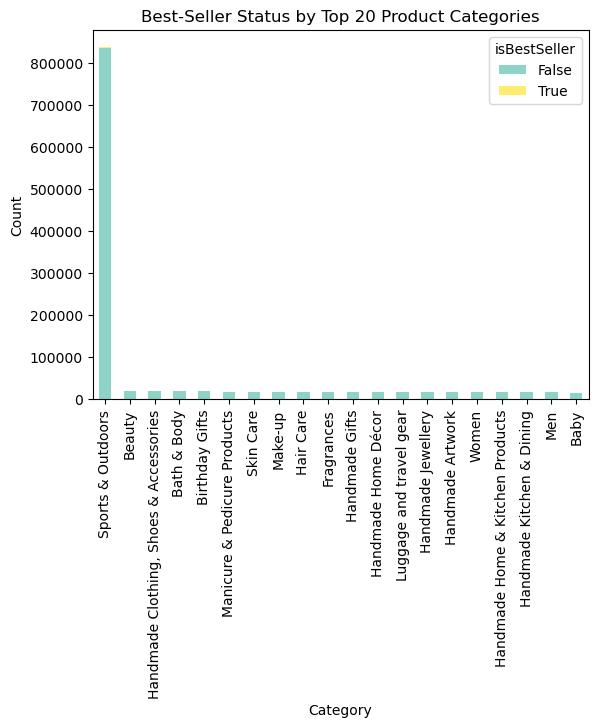

In [18]:
top_20_categories = amazon_uk_product_df["category"].value_counts().head(20).index

crosstab_top20 = crosstab_result.loc[top_20_categories]

plt.figure(figsize=(15, 6))
crosstab_top20.plot(kind="bar", stacked=True, colormap="Set3")
plt.title("Best-Seller Status by Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Count")
plt.xticks(rotation=90)
plt.show()

<Figure size 1500x600 with 0 Axes>

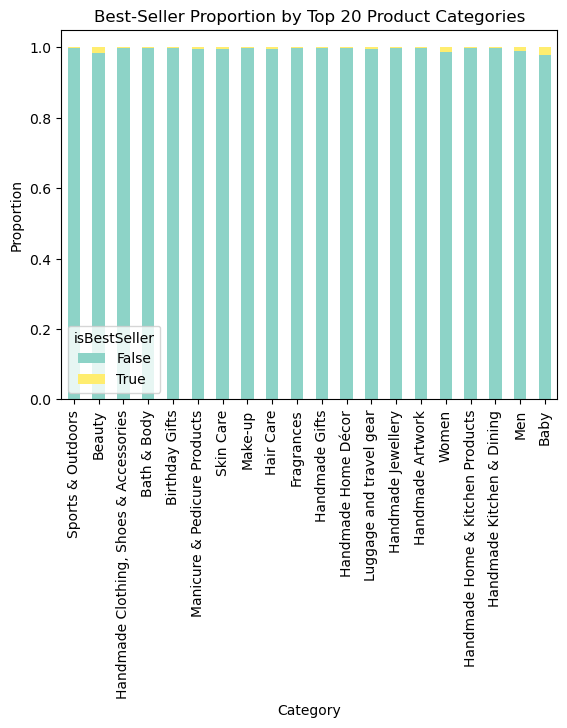

In [19]:
top_20_categories = amazon_uk_product_df["category"].value_counts().head(20).index
crosstab_top20_prop = crosstab_proportions.loc[top_20_categories]

plt.figure(figsize=(15, 6))
crosstab_top20_prop.plot(kind="bar", stacked=True, colormap="Set3")
plt.title("Best-Seller Proportion by Top 20 Product Categories")
plt.xlabel("Category")
plt.ylabel("Proportion")
plt.xticks(rotation=90)
plt.show()

**Insights:**

- The crosstab shows that the vast majority of products across all categories are not best-sellers — best-seller rates rarely exceed 5-6% in any category.
- Grocery, Smart Home Security & Lighting, and Health & Personal Care have the highest best-seller proportions at around 5.7-5.8%.
- Several categories like eBook Readers, Snowboard Boots, and Boxes & Organisers have 0% best-sellers.
- The Chi-square test (p-value = 0.0) confirms that best-seller status is statistically related to category.
- However, Cramér's V of 0.12 shows this relationship is weak and category alone is not a strong predictor of best-seller status.
- Business implication: Sellers in Grocery and Health categories have a slightly better chance of achieving best-seller status.


---
## Part 2: Exploring Product Prices and Ratings Across Categories and Brands

**Objective**: Investigate how different product categories influence product prices.

### 2.0 Preliminary Step: Remove Outliers in Product Prices
Use the IQR method to remove outliers:
- Products priced below **Q1 - 1.5 x IQR** or above **Q3 + 1.5 x IQR** are considered outliers.
- All following steps should use this cleaned DataFrame.

In [24]:
# Calculating Q1, Q3 and IQR
Q1 = amazon_uk_product_df["price"].quantile(0.25)
Q3 = amazon_uk_product_df["price"].quantile(0.75)
IQR = Q3 - Q1

# Defining lower and upper bounds
lower_bound = Q1 - 1.5 * IQR
upper_bound = Q3 + 1.5 * IQR

# Filtering out outliers
amazon_uk_product_df_no_outliers = amazon_uk_product_df[
    (amazon_uk_product_df["price"] >= lower_bound) & 
    (amazon_uk_product_df["price"] <= upper_bound)
]

print("Original shape:", amazon_uk_product_df.shape)
print("After removing outliers:", amazon_uk_product_df_no_outliers.shape)

Original shape: (2443651, 8)
After removing outliers: (2115963, 8)


### 2.1 Violin Plots
- Use a violin plot to visualize the distribution of `price` across different product `categories`.
- Filter out the **top 20 categories** based on count for better visualization.
- Which product category tends to have the highest median price? (Don't filter for this answer)

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_9712/3408201097.py:1: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=amazon_uk_product_df_no_outliers, x='category', y='price', palette="coolwarm")


<Axes: xlabel='category', ylabel='price'>

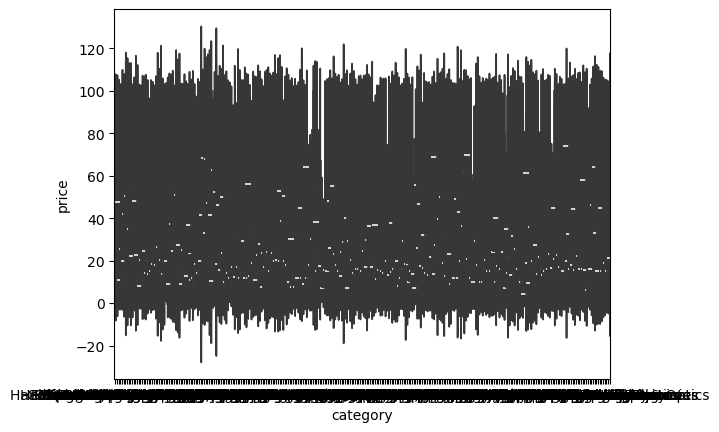

In [26]:
sns.violinplot(data=amazon_uk_product_df_no_outliers, x='category', y='price', palette="coolwarm")

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_9712/2282250679.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")


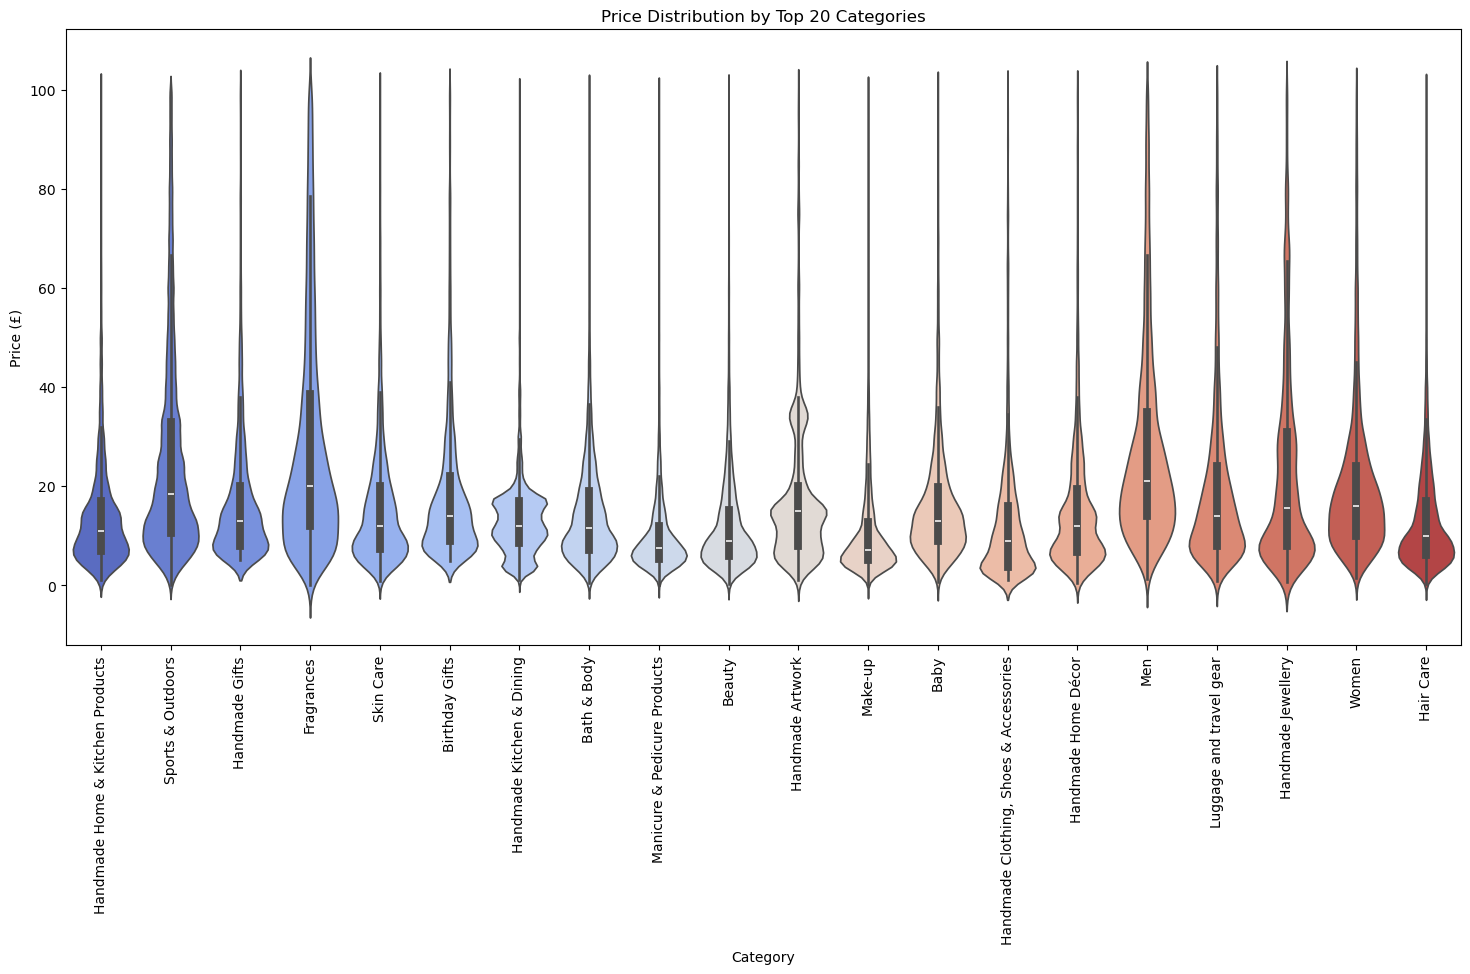

In [27]:
top_20_categories = amazon_uk_product_df_no_outliers["category"].value_counts().head(20).index
df_top20 = amazon_uk_product_df_no_outliers[amazon_uk_product_df_no_outliers["category"].isin(top_20_categories)]

plt.figure(figsize=(18, 8))
sns.violinplot(data=df_top20, x="category", y="price", palette="coolwarm")
plt.title("Price Distribution by Top 20 Categories")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=90)
plt.show()

In [28]:
amazon_uk_product_df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False).head(10)

category
Desktop PCs               74.00
Boxing Shoes              69.79
Tablets                   69.00
Graphics Cards            68.54
Motherboards              67.92
Made in Italy Handmade    64.00
Digital Frames            63.90
Streaming Clients         62.68
Golf Shoes                62.39
Ski Helmets               61.33
Name: price, dtype: float64

### 2.2 Bar Charts
- Create a bar chart comparing the average price of products for the **top 10 product categories** (based on count).
- Which product category commands the highest average price? (Don't filter for this answer)

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_9712/3778025826.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm")


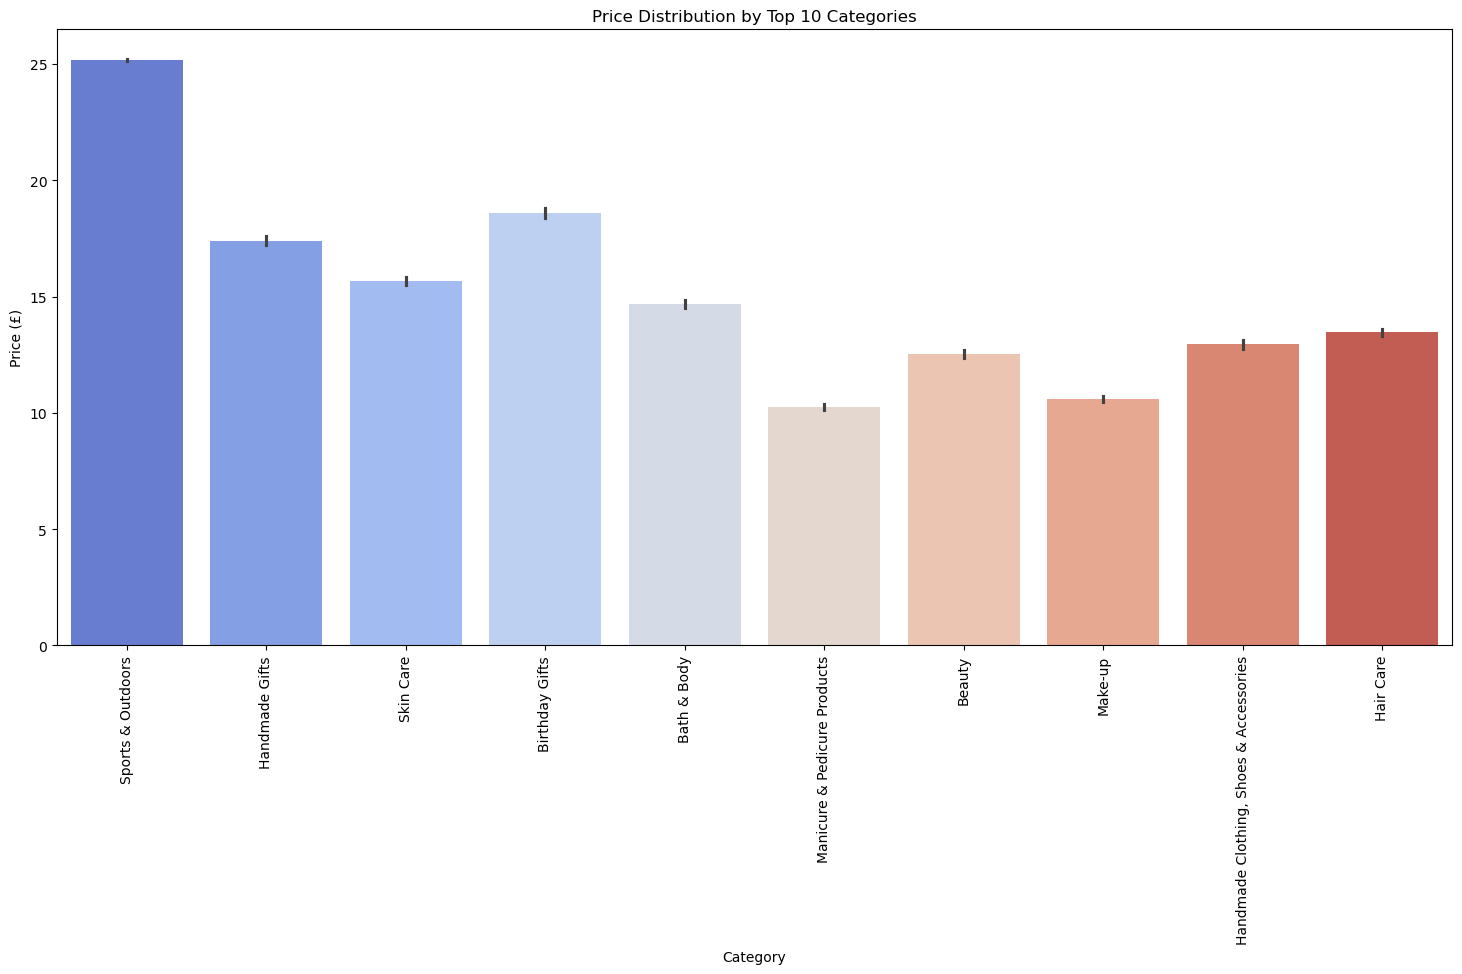

In [29]:
top_10_categories = amazon_uk_product_df_no_outliers["category"].value_counts().head(10).index
df_top10 = amazon_uk_product_df_no_outliers[amazon_uk_product_df_no_outliers["category"].isin(top_10_categories)]

plt.figure(figsize=(18, 8))
sns.barplot(data=df_top10, x="category", y="price", palette="coolwarm")
plt.title("Price Distribution by Top 10 Categories")
plt.xlabel("Category")
plt.ylabel("Price (£)")
plt.xticks(rotation=90)
plt.show()


In [30]:
amazon_uk_product_df_no_outliers.groupby("category")["price"].median().sort_values(ascending=False).head(5)

category
Desktop PCs       74.00
Boxing Shoes      69.79
Tablets           69.00
Graphics Cards    68.54
Motherboards      67.92
Name: price, dtype: float64

### 2.3 Box Plots
- Visualize the distribution of product `ratings` based on their `category` using side-by-side box plots.
- Filter out the **top 10 categories** based on count for better visualization.
- Which category tends to receive the highest median rating? (Don't filter for this answer)

/var/folders/lg/5zr61f512tn2t5yg6hpddmsm0000gn/T/ipykernel_9712/2524617273.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(data=df_top10_rated, x="category", y="stars", palette="coolwarm")


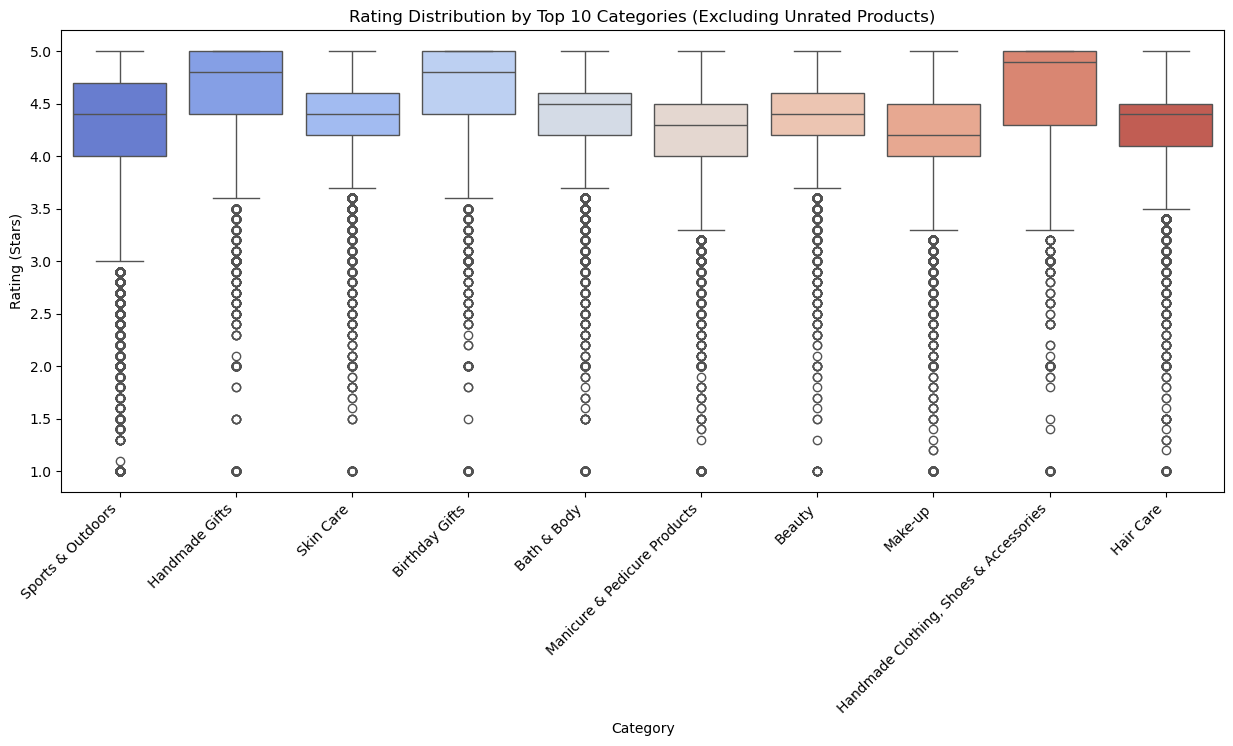

In [34]:
df_top10_rated = df_top10[df_top10["stars"] > 0]

plt.figure(figsize=(15, 6))
sns.boxplot(data=df_top10_rated, x="category", y="stars", palette="coolwarm")
plt.title("Rating Distribution by Top 10 Categories (Excluding Unrated Products)")
plt.xlabel("Category")
plt.ylabel("Rating (Stars)")
plt.xticks(rotation=45, ha="right")
plt.show()

In [35]:
amazon_uk_product_df_no_outliers[amazon_uk_product_df_no_outliers["stars"] > 0].groupby("category")["stars"].median().sort_values(ascending=False).head(5)

category
Made in Italy Handmade                    5.0
Handmade Baby Products                    5.0
Handmade Artwork                          5.0
Handmade Kitchen & Dining                 4.9
Handmade Clothing, Shoes & Accessories    4.9
Name: stars, dtype: float64

**Insights:**

-- Pricing:

- After removing outliers, 327,688 rows (13%) were removed.
- Sports & Outdoors has the highest average price (~£25) among the top 10 most listed categories.
- When looking at all 296 categories, Desktop PCs has the highest median price at £74, followed by Boxing Shoes (£69.79) and Tablets (£69) — all tech/electronics or specialist sports categories.
- Most categories have their bulk of products priced under £25, with prices heavily concentrated in the £10-£20 range.
- Manicure & Pedicure Products and Bath & Body are the most affordable categories with consistent low prices.
- Business implication: Tech and electronics categories command significantly higher prices. Sellers in these categories can expect higher revenue per sale but face more price-sensitive customers.

-- Ratings:

- After filtering out unrated products, all top 10 categories have median ratings above 4.0 stars. 
- Handmade Clothing, Shoes & Accessories has the highest median rating at ~4.9 — handmade products tend to receive very positive feedback.
- Manicure & Pedicure Products and Make-up have the lowest median ratings around 4.2-4.3 — possibly due to higher customer expectations in beauty categories. 
- All categories show outliers at 1.0-2.0 stars — no category is immune to negative reviews.
- Business implication: Handmade and gift categories consistently receive the highest ratings, suggesting strong customer satisfaction in these niche markets.


---
## Part 3: Investigating the Interplay Between Product Prices and Ratings

**Objective**: Analyze how product ratings (`stars`) correlate with product prices.

### 3.1 Correlation Coefficients
- Calculate the correlation coefficient between `price` and `stars`.
- Is there a significant correlation between product price and its rating?

In [36]:
correlation = amazon_uk_product_df['price'].corr(amazon_uk_product_df['stars'])
correlation

np.float64(-0.12490673262148537)

### 3.2 Scatter Plot
Use a scatter plot to visualize the relationship between product rating and price.
What patterns can you observe?

<Axes: xlabel='stars', ylabel='price'>

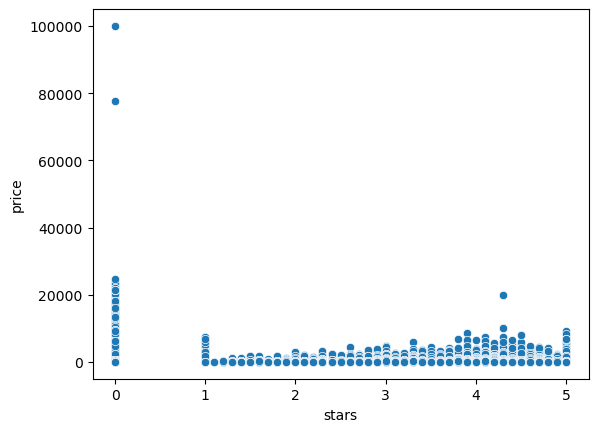

In [37]:
sns.scatterplot(data=amazon_uk_product_df, x='stars', y='price')

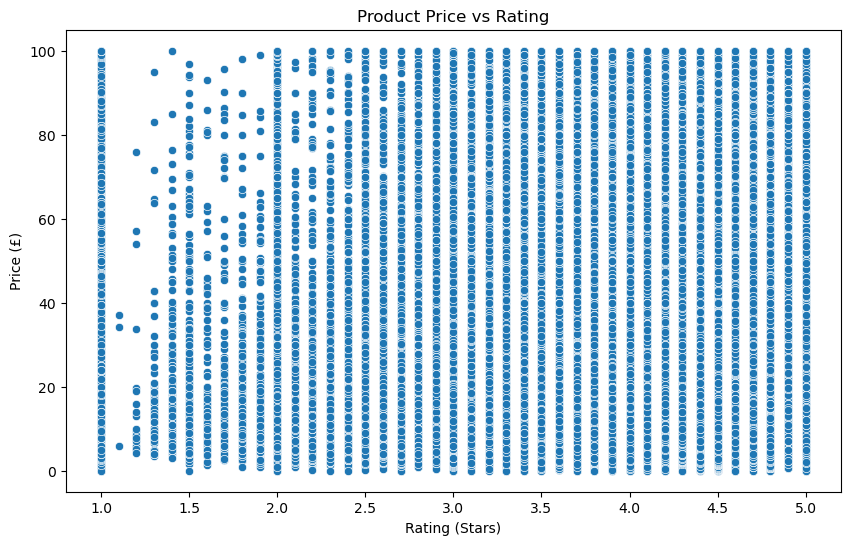

In [39]:
df_rated = amazon_uk_product_df_no_outliers[amazon_uk_product_df_no_outliers["stars"] > 0]

plt.figure(figsize=(10, 6))
sns.scatterplot(data=df_rated, x="stars", y="price")
plt.title("Product Price vs Rating")
plt.xlabel("Rating (Stars)")
plt.ylabel("Price (£)")
plt.show()

### 3.3 Correlation Heatmap
Use a correlation heatmap to visualize correlations between all numerical variables.

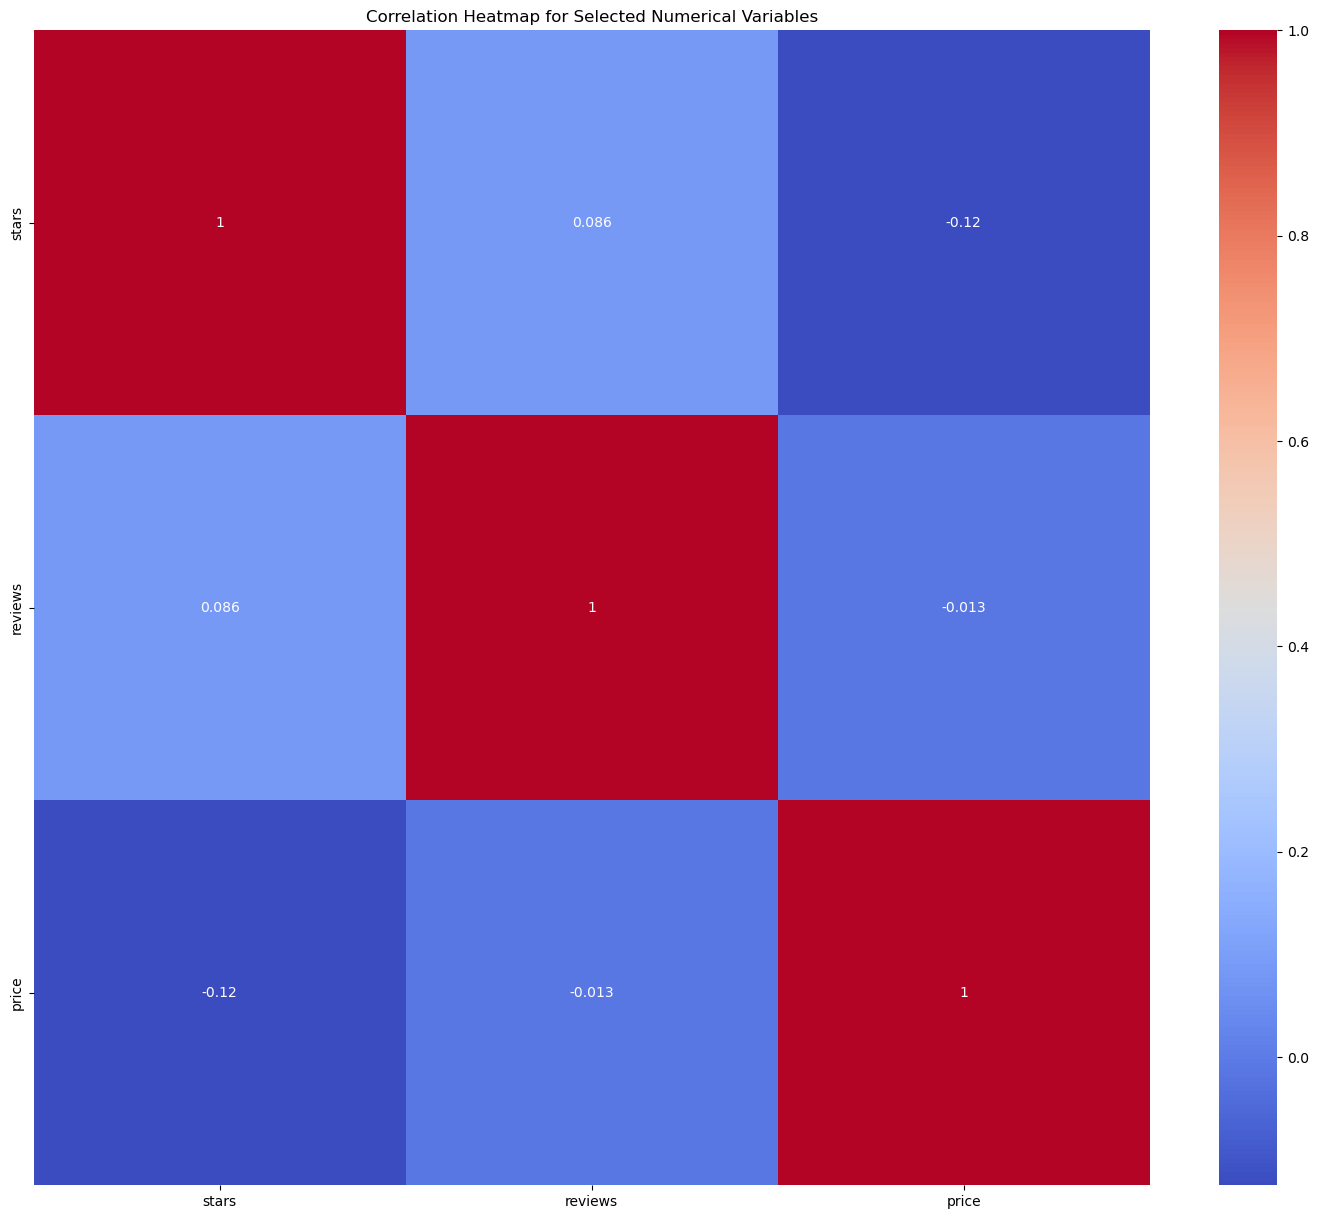

In [40]:
correlation_matrix = amazon_uk_product_df_numerical.corr()
plt.figure(figsize=(18, 15))
sns.heatmap(correlation_matrix, annot=True, cmap="coolwarm")
plt.title("Correlation Heatmap for Selected Numerical Variables")
plt.show()

### 3.4 QQ Plot
Examine if product prices typically follow a normal distribution using a QQ plot.

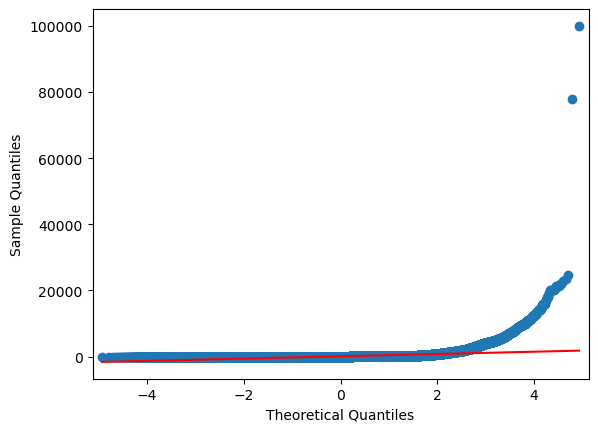

In [41]:
import statsmodels.api as sm

sm.qqplot(amazon_uk_product_df['price'], line='s');

**Insights:**

-- Correlation:

- The correlation between price and stars is -0.12 — an extremely weak negative relationship.
- In practical terms, price and ratings are essentially independent — expensive products do not get better ratings, and cheap products do not get worse ratings.
- The correlation heatmap confirms this across all numerical variables — stars, reviews, and price are all essentially unrelated to each other.
- The strongest relationship found is stars vs reviews at 0.086 — still very weak.

-- Scatter Plot:

- The scatter plot visually confirms the lack of relationship — points are spread randomly across all price levels for every rating value.
- The densest area is between 4.0-5.0 stars regardless of price — confirming that most products are highly rated at any price point.

-- QQ Plot:

- Product prices do not follow a normal distribution.
- The QQ plot shows points deviating sharply from the red line on the right side — caused by extreme high-price outliers.
- This confirms the heavy right skew we identified in the histogram — most products are cheap but a few very expensive products pull the distribution.
- Business implication: Price alone is not a driver of customer satisfaction on Amazon UK. Sellers should focus on product quality and customer experience rather than pricing strategy to achieve higher ratings.
